# Day 2 - Exploratory Data Analysis: NYC Yellow Taxi, Jan-Jun 2024

**Data:** the *cleaned* trips from Task 5 (`data/processed/`, 19,656,373 trips). The outlier chart also uses the raw files to show what cleaning removed.

**Method (memory-friendly):**
- Counts and trends are computed by **DuckDB** over *all* cleaned rows. Only small results come back to pandas.
- Row-level charts (distributions, scatter, box plots, correlation) use a reproducible **random sample of 300,000 trips** (seed 42).
- The chart code lives in [`src/eda/charts.py`](../src/eda/charts.py), so it is reusable and reviewable. This notebook calls it and records one takeaway per chart.
- Every chart is also saved to `reports/figures/`.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt

from eda import charts as c

c.apply_style()
con = c.connect()
clean = c.sample(con, "clean")
raw = c.sample(con, "raw")
print(f"Sample sizes: clean {len(clean):,} rows, raw {len(raw):,} rows")

Sample sizes: clean 300,000 rows, raw 300,000 rows


## 1. Distributions: distance, fare and duration

*Question:* What does a typical trip look like?

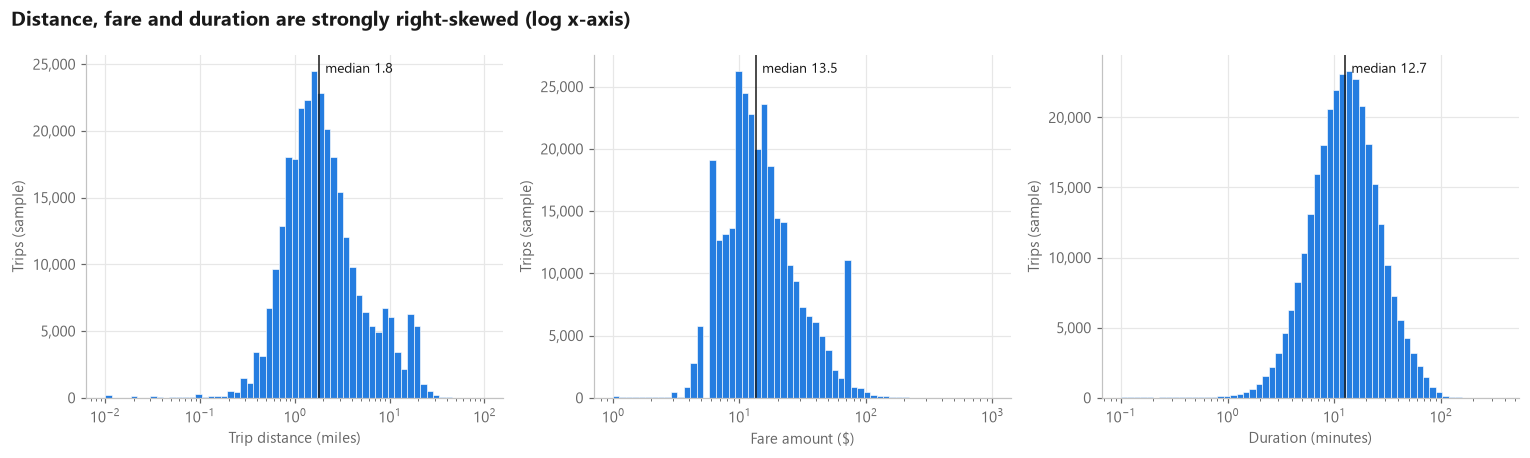

In [2]:
fig = c.plot_distributions(clean)
c.save(fig, "day2_01_distributions")
plt.show()

**Takeaway:** All three are heavily right-skewed. The typical trip is short (median 1.8 miles, \$13.50, 12.7 minutes), but a long tail of airport and out-of-town trips stretches the range, so **log scales and medians describe this data better than linear axes and means.**

## 2. Fare vs distance

*Question:* How closely does the fare follow the meter?

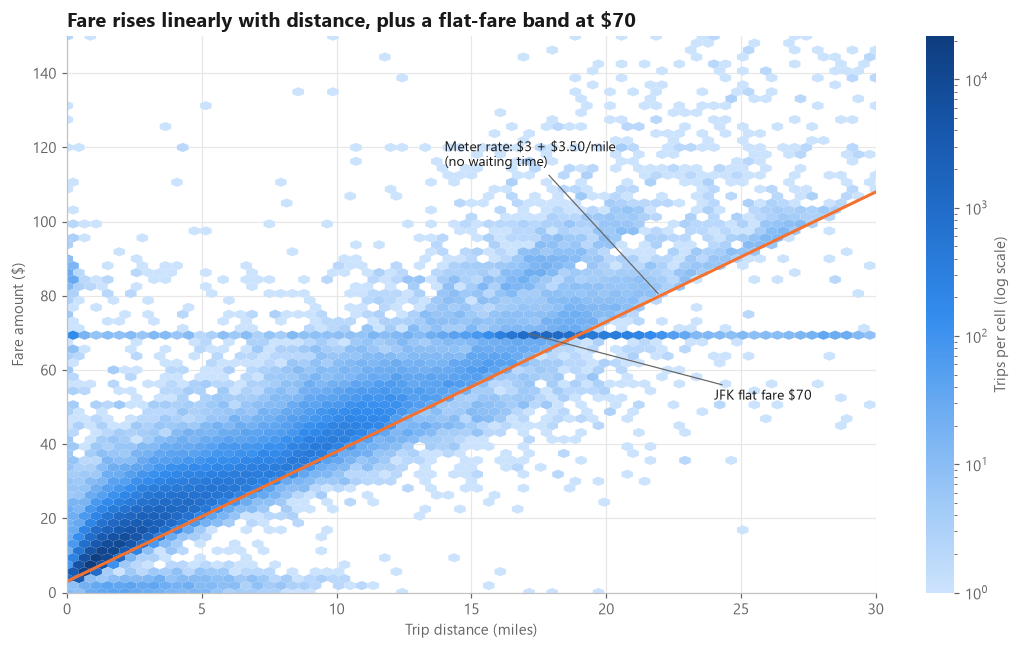

In [3]:
fig = c.plot_fare_vs_distance(clean)
c.save(fig, "day2_02_fare_vs_distance")
plt.show()

**Takeaway:** Fare follows distance closely (Spearman 0.91) and usually sits *above* the meter line, because time stuck in traffic is also charged. The horizontal band at \$70 is the JFK flat fare (3.3% of trips), so **a fare model must treat airport flat fares separately.**

## 3. Tip % by payment type

*Question:* Who tips, and how much?

,payment_type,trips,avg_tip_pct,pct_with_tip,payment
0,0,1789798,3.84,17.59,Flex Fare
1,1,14974150,25.29,94.82,Credit card
2,2,2653122,0.00,0.00,Cash
3,3,70437,0.04,0.09,No charge
4,4,164238,0.08,0.11,Dispute


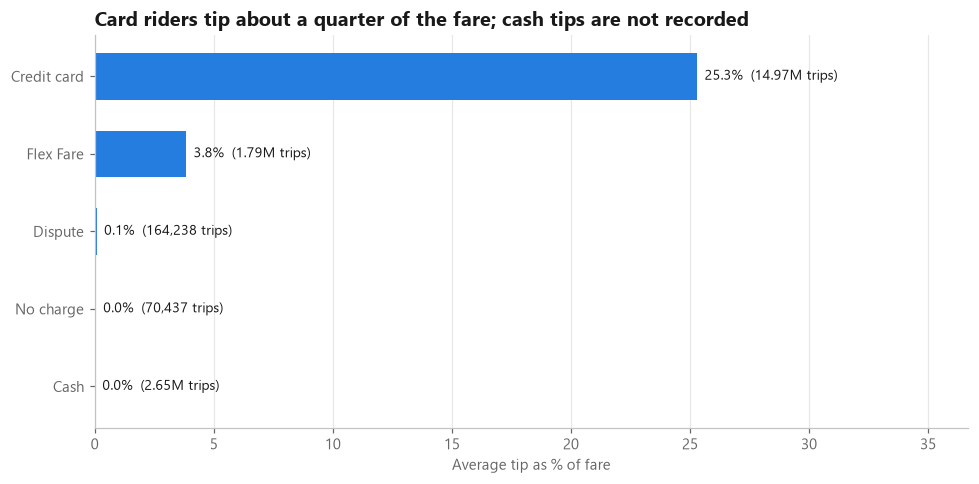

In [4]:
tips = c.tip_by_payment(con)
display(tips.round(2))
fig = c.plot_tip_by_payment(tips)
c.save(fig, "day2_03_tip_by_payment")
plt.show()

**Takeaway:** Credit-card riders tip 25.3% of the fare on average, and 95% of them leave a tip. Cash shows 0% only because **cash tips are not recorded**, so tip analysis must use card trips only.

## 4. Seasonality: hour of day x day of week

*Question:* When is demand highest?

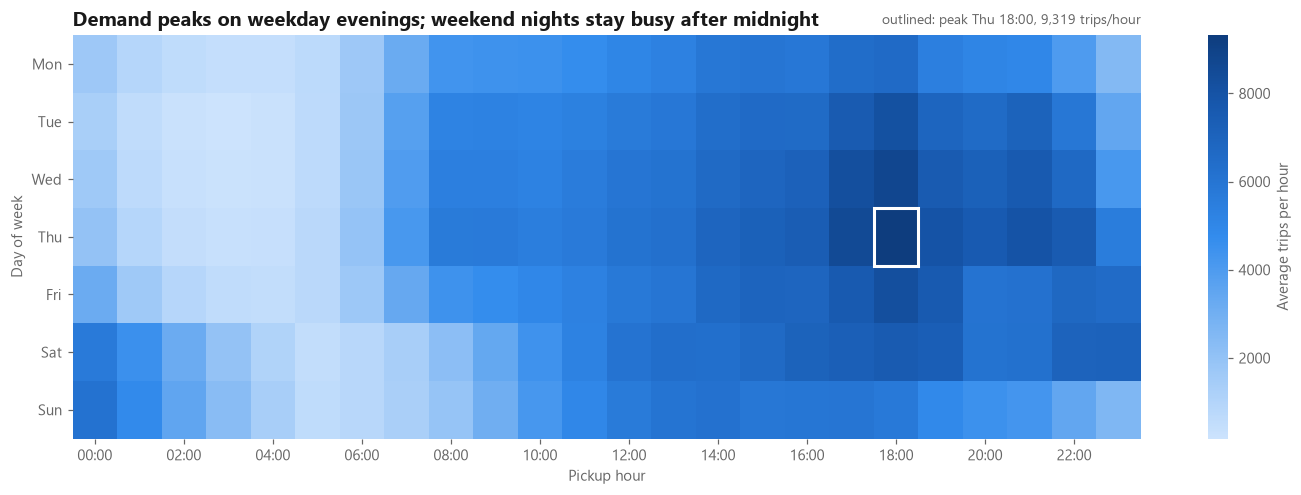

In [5]:
hw = c.hourly_weekday(con)
fig = c.plot_hour_weekday_heatmap(hw)
c.save(fig, "day2_04_hour_weekday_heatmap")
plt.show()

**Takeaway:** Demand peaks on **weekday evenings (Thursday 18:00, about 9,300 trips per hour)** and is lowest at 3-5 am on weekdays. Between midnight and 3 am, weekend nights are about 4x busier than weekday nights.

## 5. Demand by borough

*Question:* Where do trips start?

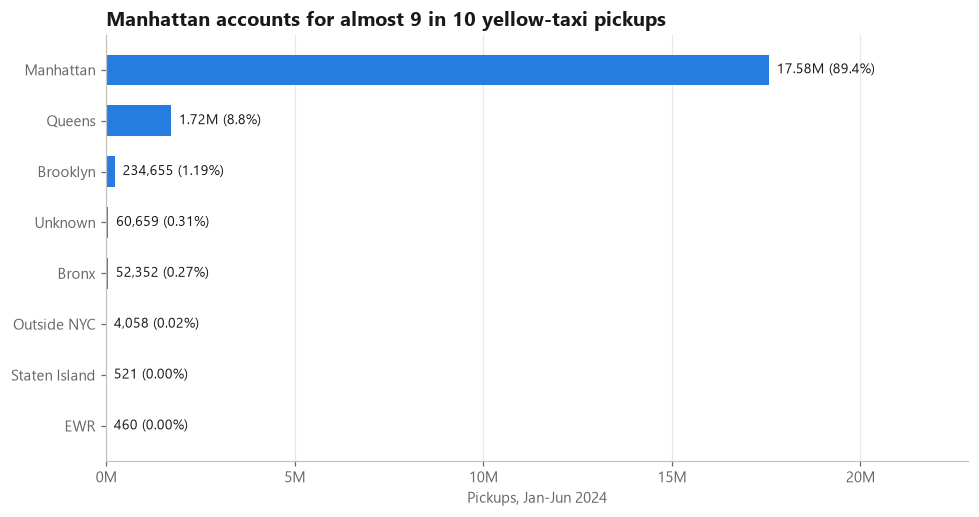

In [6]:
boroughs = c.demand_by_borough(con)
fig = c.plot_demand_by_borough(boroughs)
c.save(fig, "day2_05_demand_by_borough")
plt.show()

**Takeaway:** Manhattan accounts for **89.4% of pickups** and Queens (mostly the airports) for 8.8%. Yellow taxis are essentially a Manhattan-and-airports service, so analysis of the outer boroughs needs other data, such as green taxi or for-hire vehicle trips.

## 6. Outliers: raw vs cleaned

*Question:* What did cleaning remove, and what outliers remain?

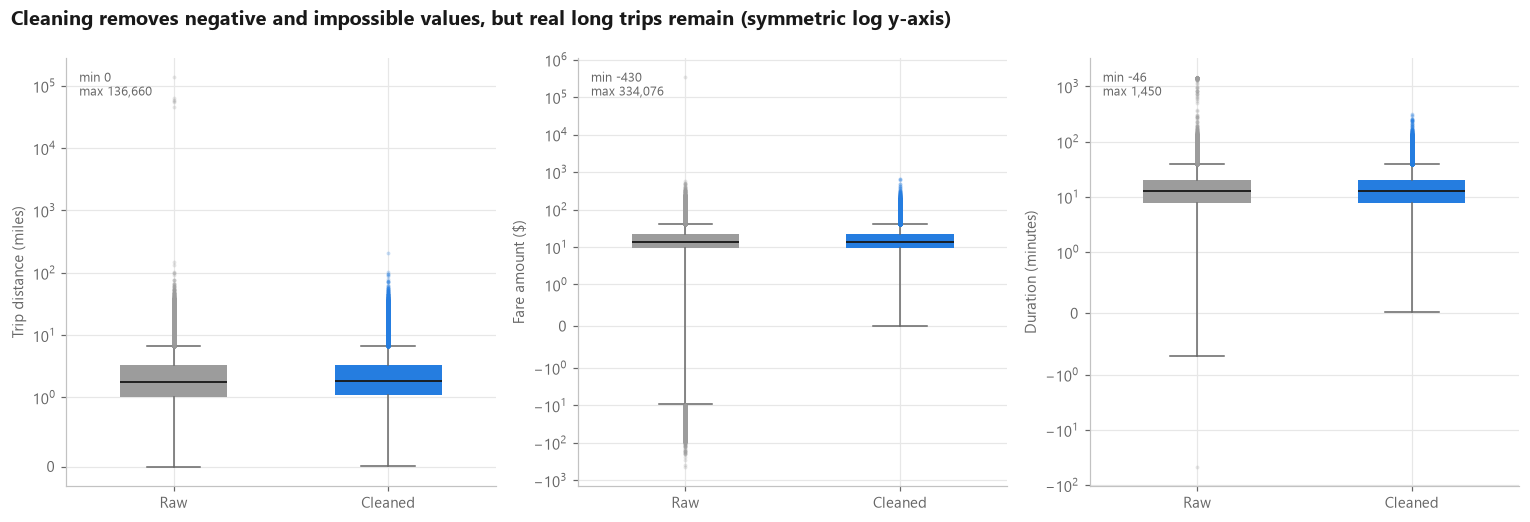

In [7]:
fig = c.plot_outlier_boxplots(raw, clean)
c.save(fig, "day2_06_outlier_boxplots")
plt.show()

**Takeaway:** The raw data contains **impossible values** (in this sample: fares down to -\$430, a 136,660-mile trip and negative durations), and cleaning removes them. The cleaned data still has long but plausible trips, so **the remaining outliers are real behaviour, not errors.**

## 7. Correlation heatmap

*Question:* Which numeric fields move together?

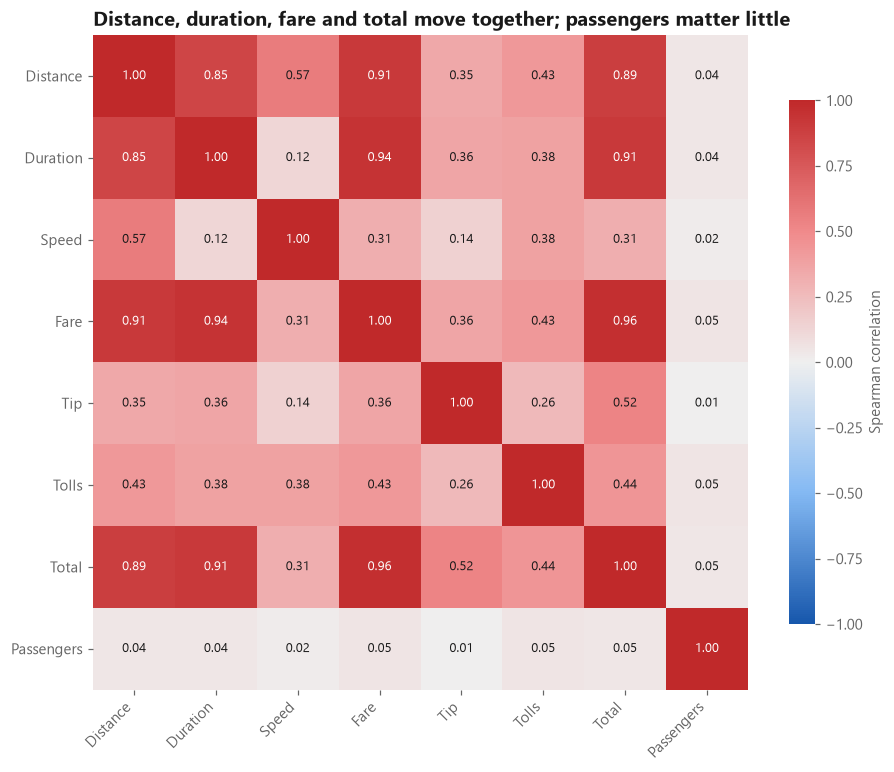

In [8]:
fig = c.plot_correlation(clean)
c.save(fig, "day2_07_correlation")
plt.show()

**Takeaway:** Fare is driven by **duration (0.94) and distance (0.91)**, tips relate only moderately to fare (0.36), and **passenger count has almost no relationship with anything (at most 0.05)**, so it is a weak feature for fare or tip prediction. Spearman (rank) correlation is used because the data is skewed and has outliers.

## 8. Monthly trend

*Question:* Is the business growing?

,month,trips,revenue
0,2024-01-01,2867136,7.837042e+07
1,2024-02-01,2899131,7.893919e+07
2,2024-03-01,3437443,9.573390e+07
3,2024-04-01,3411731,9.614410e+07
4,2024-05-01,3615195,1.047923e+08
5,2024-06-01,3425737,9.825551e+07


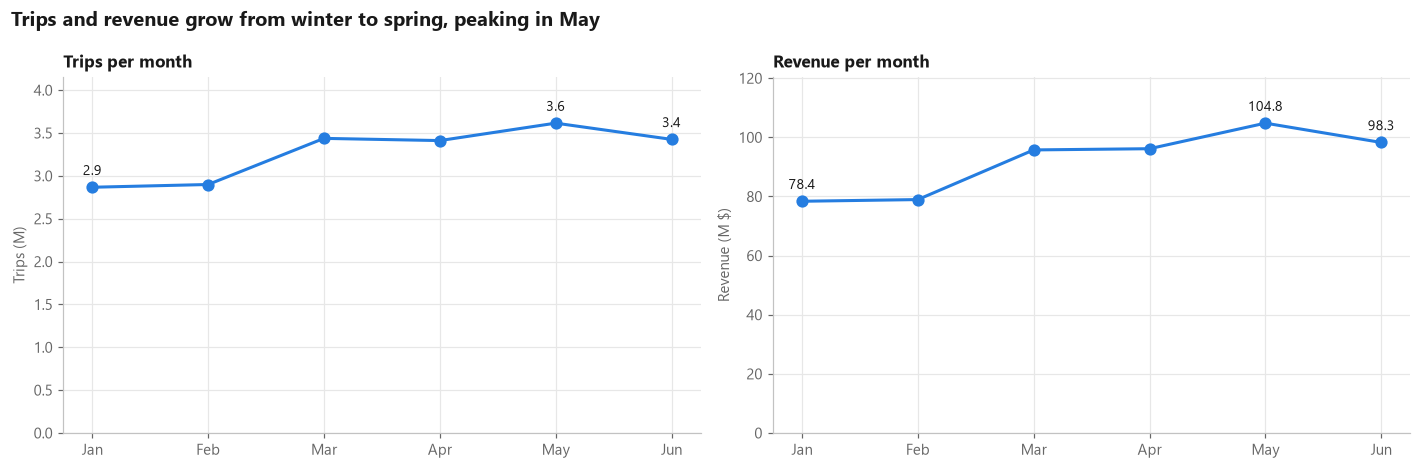

In [9]:
monthly = c.monthly_trend(con)
display(monthly)
fig = c.plot_monthly_trend(monthly)
c.save(fig, "day2_08_monthly_trend")
plt.show()

**Takeaway:** Trips grew from 2.87M in January to a **peak of 3.62M in May (+26%)**, and revenue from \$78.4M to \$104.8M, with the biggest step in March. Six months is too short to tell seasonality apart from long-term growth.

## 9. Daily trips and 7-day rolling average

*Question:* How much does demand vary day to day?

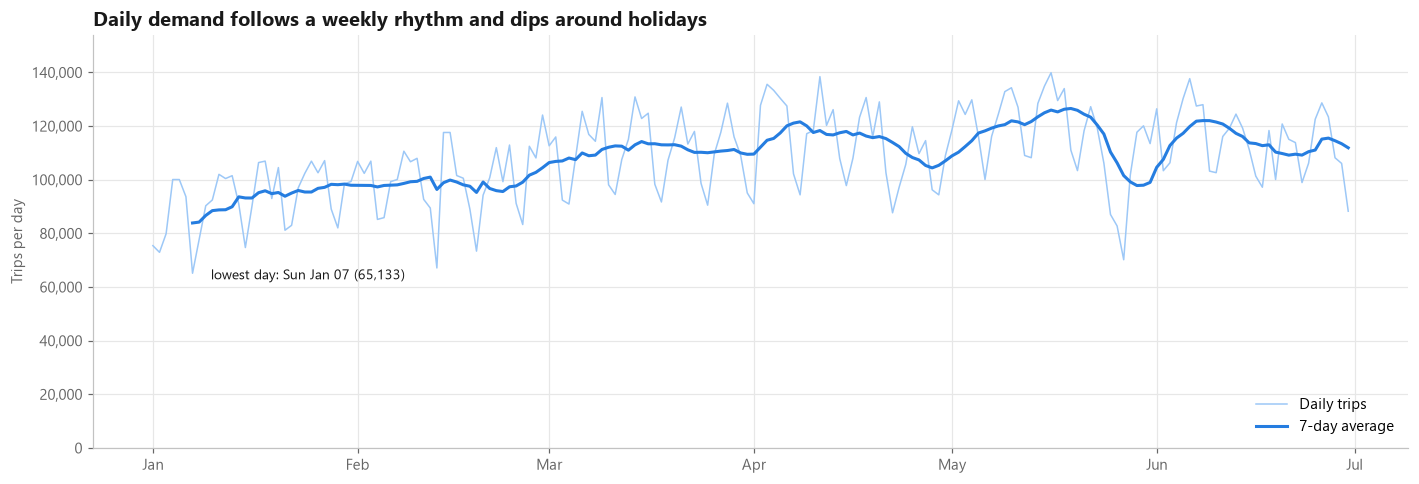

weekday
Monday        90456.0
Sunday        95768.0
Tuesday      106016.0
Friday       113041.0
Wednesday    114021.0
Saturday     115161.0
Thursday     121551.0
Name: trips, dtype: float64

In [10]:
daily = c.daily_trips(con)
fig = c.plot_daily_trips(daily)
c.save(fig, "day2_09_daily_trips")
plt.show()
daily.assign(weekday=daily["day"].dt.day_name()).groupby("weekday")["trips"].mean().sort_values().round(0)

**Takeaway:** Daily trips swing strongly within each week: **Thursdays average 34% more trips than Mondays** (121.6k vs 90.5k). The 7-day average removes that rhythm and shows the trend. Holiday weekends, such as Memorial Day (May 27), are clearly visible as dips.

## Summary for modelling

1. **Use medians and log scales.** Distance, fare and duration are right-skewed.
2. **Fare ≈ meter(distance, time) + flat-fare exceptions.** Airport flat fares need their own feature.
3. **Tips are only reliable for card payments.** Exclude cash from tip analysis.
4. **Time features matter.** Hour of day and day of week drive demand strongly.
5. **Passenger count is a weak predictor.**
6. **The cleaned data has no impossible values.** The remaining outliers are real and should be kept.